## 02 – Modelling: Detecting Credit Card Fraud

**Goal:** Train a model to spot fraudulent transactions, then estimate how much money it would save.

**What we learned in notebook 1:**
- Fraud is very rare (0.167%), so accuracy is misleading. Models are judged on how much fraud they catch (**recall**)
  and how many of their alerts are correct (**precision**).
- Fraud happens more at night, so the hour of the transaction is given to the model.

**Steps:** prepare the data → simple baseline → two models → compare → what the best model relied on.
The money saved is estimated in `03_business_impact.ipynb`.

### Setup

Load the data and remove duplicates (the checks are in notebook 1). Add an `hour` column, since fraud is more common at night.

In [53]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
#sklearn - Python’s main machine learning library
from sklearn.model_selection import train_test_split
#Splits the data into the 80% training and 20% test parts
from sklearn.dummy import DummyClassifier
#The “lazy” model that always guesses normal (baseline)
from sklearn.linear_model import LogisticRegression
#Model 1, the simple formula model
from sklearn.ensemble import RandomForestClassifier
#Model 2, the 100 voting decision trees
from sklearn.pipeline import make_pipeline
#Chains steps together, so scaling then the model happen as one
from sklearn.preprocessing import StandardScaler
#Puts all features on the same scale
from sklearn.metrics import (accuracy_score, precision_score, recall_score, average_precision_score)

database_connection = duckdb.connect()
DATA_PATH = "../data/creditcard.csv"

#Load the CSV and remove duplicate rows
database_connection.execute(f"""
CREATE OR REPLACE TABLE transactions AS
SELECT DISTINCT * FROM read_csv_auto('{DATA_PATH}')
ORDER BY ALL
""")

#Add the hour of day (0-23) and turn it into a table
df = database_connection.execute("""
SELECT *, CAST(FLOOR(Time / 3600) AS INTEGER) % 24 AS hour
FROM transactions
""").df()

print(f"{len(df):,} transactions, {int(df['Class'].sum())} fraud")

283,726 transactions, 473 fraud


### Prepare the data

Before training, we set up a fair "exam" for the model.

**1. Clues and answers**
- **Inputs (`X`):** the clues the model is allowed to look at: `V1`–`V28` (anonymised transaction details), `Amount` and `hour`.
  The raw `Time` column is left out, since it only counts seconds across these two specific days; `hour` keeps the useful part.
- **Answer (`y`):** what the model has to predict: `Class` (1 = fraud, 0 = normal).
- The answer must never be included in the clues. Otherwise the model would just "read the answer sheet" and learn nothing.

**2. Training and testing**
- In real life, a bank's model only ever sees *new* transactions. So we hide 20% of the data, let the model learn from the other 80%,
  then test it on the hidden part.
- Without this, we'd be testing the model on transactions it has already seen. It could score perfectly by memorising them,
  like a student who memorised last year's exam paper but can't answer new questions.

**3. Settings used**
- `test_size=0.2`: 20% of transactions are kept for testing.
- `stratify=y`: keeps the fraud rate the same (0.167%) in both parts, so the few frauds aren't split unevenly by chance.
- `random_state=42`: makes the split the same every time the notebook runs, so results can be reproduced.

In [54]:
#Builds a list of columns: V1, ... V28, Amount, hour the model may look at:
features = [f"V{i}" for i in range(1, 29)] + ["Amount", "hour"]
X = df[features]
y = df["Class"]

#Shuffles the rows and splits them into four pieces:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Training set: {len(X_train):,} transactions ({int(y_train.sum())} fraud)")
print(f"Test set: {len(X_test):,} transactions ({int(y_test.sum())} fraud)")

Training set: 226,980 transactions (378 fraud)
Test set: 56,746 transactions (95 fraud)


### How models are scored

We'll build three models, so we need one consistent way to mark them. This function grades any model on the test set
and adds its scores to a comparison table.

- **Accuracy:** share of all predictions that were right. Shown for comparison, but misleading here because fraud is so rare.
- **Recall:** of all the real frauds, how many did the model catch? *(Missing fraud costs money.)*
- **Precision:** of the transactions the model flagged as fraud, how many really were? *(False alarms annoy genuine customers.)*
- **PR-AUC (Precision Recall-Area Under the Curve):** one overall score from 0 to 1 for how well the model ranks frauds above normal transactions,
  regardless of where the "fraud" cut-off is set. Higher is better, and it's the main score used to compare models.

The function uses two kinds of output from each model:
- **Predictions:** a final answer for each transaction (0 = normal, 1 = fraud).
- **Probabilities:** how confident the model is that each transaction is fraud (0 to 1). These are needed for PR-AUC
  and later for choosing the best cut-off.

In [55]:
results = {}

def evaluate(name, model):
    predictions = model.predict(X_test)
    #The model’s final answer for each test transaction: 0 (normal) or 1 (fraud).
    probabilities = model.predict_proba(X_test)[:, 1]
    #How confident the model is that each transaction is fraud, from 0.00 to 1.00
    results[name] = {
        "accuracy": accuracy_score(y_test, predictions),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "pr_auc": average_precision_score(y_test, probabilities),
    }
    return pd.DataFrame(results).T.round(3)

### Baseline: the "lazy" model

A model that predicts "normal" for every transaction. Any real model has to beat this.

In [56]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
evaluate("Baseline (always normal)", baseline)

,accuracy,recall,precision,pr_auc
Baseline (always normal),0.998,0.0,0.0,0.002


### Model 1: Logistic regression

**What it is:** a simple, fast model. It gives each clue a weight (how much it points towards fraud), adds them up into a score,
and turns that score into a fraud probability between 0 and 1. It's a common first model to try.

**Settings:**
- **StandardScaler():** rescales every feature so they’re comparable. `Amount` goes up to 25,000, while V features sit near 0. Without scaling, the model would treat `Amount` as hugely more important just because its numbers are bigger.
- **LogisticRegression(...):** is the model itself. It learns a weight for each feature, adds them up into a score, and turns that into a fraud probability.
- **class_weight="balanced":** because fraud is so rare, each fraud case is treated as hundreds of times more important during training. Otherwise the model would copy the lazy baseline.
- **max_iter=1000:** lets it take up to 1,000 learning steps. The default (100) sometimes isn’t enough, and you’d get a warning.

The two steps are joined in a **pipeline**, so the scaling is always applied, both when training and when predicting, so you can’t accidentally forget it.

In [57]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)
log_reg.fit(X_train, y_train)
#Training: the model studies the training clues and answers and learns its weights.
evaluate("Logistic regression", log_reg)

,accuracy,recall,precision,pr_auc
Baseline (always normal),0.998,0.000,0.000,0.002
Logistic regression,0.976,0.874,0.057,0.668


**Result:** Logistic regression catches 87% of fraud (83 of 95), but only 5.7% of its alerts are real fraud,
meaning around 1,369 genuine customers would be wrongly flagged. It's over-cautious: good at catching fraud, bad at avoiding false alarms.

### Model 2: Random forest

**What it is:** a model made of **100 decision trees**. Each tree is a flowchart of yes/no questions the model works out for itself,
e.g. *"Is V14 very low? Is the amount under 10?"* → fraud or normal.

**Why 100 trees?** A single tree makes mistakes by latching onto quirks in the data. Each tree here is trained on a random sample
of transactions and clues, so they all make *different* mistakes. When they **vote**, those mistakes mostly cancel out,
like averaging 100 people's guesses instead of trusting one.

**Settings:**
- `n_estimators=100`: number of trees.
- `n_jobs=-1`: use all the computer's processor cores to train faster (this cell still takes a little while).
- `random_state=42`: makes the randomness repeatable, so results are the same each run.

In [58]:
forest = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
forest.fit(X_train, y_train)
evaluate("Random forest", forest)

,accuracy,recall,precision,pr_auc
Baseline (always normal),0.998,0.000,0.000,0.002
Logistic regression,0.976,0.874,0.057,0.668
Random forest,0.999,0.716,0.932,0.764


**Result:** The random forest catches 72% of fraud (68 of 95), and 93% of its alerts are real fraud, with only 5 false alarms.
Compared with logistic regression, it misses 15 more frauds but avoids 1,364 false alarms.
It also has the higher PR-AUC (0.764 vs 0.668), so it's the best model overall.

### Comparing the models

The table shows all the scores side by side. The chart shows the trade-off between catching fraud (recall)
and raising correct alerts (precision).

In [59]:
comparison = pd.DataFrame(results).T.round(3)
comparison.columns = ["Accuracy", "Recall", "Precision", "PR-AUC"]
comparison

,Accuracy,Recall,Precision,PR-AUC
Baseline (always normal),0.998,0.000,0.000,0.002
Logistic regression,0.976,0.874,0.057,0.668
Random forest,0.999,0.716,0.932,0.764


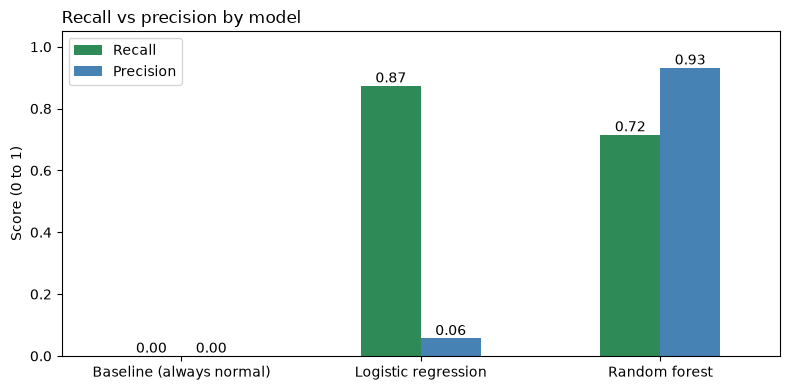

In [60]:
ax = comparison[["Recall", "Precision"]].plot(kind="bar", color=["seagreen", "steelblue"], rot=0, figsize=(8, 4))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f")   #Writes the score on top of each bar
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score (0 to 1)")
ax.set_title("Recall vs precision by model", loc="left")
plt.tight_layout()
plt.savefig("../images/model_comparison.png", dpi=150)
plt.show()

**Findings:**
- **Logistic regression** catches 83 of 95 frauds but wrongly flags 1,369 genuine customers. It's over-cautious.
- **Random forest** catches 68 of 95 frauds with only 5 false alarms. It misses more fraud, but almost never bothers genuine customers.
- Logistic regression's 15 extra catches cost 1,364 extra false alarms, a poor trade for a bank.
  The random forest also has the higher PR-AUC, so it's chosen as the best model.
- At the default cut-off (50%), the random forest still misses 27 frauds. `03_business_impact.ipynb` tests whether
  a different cut-off catches more fraud profitably.